In [52]:
import os
import filecmp
import numpy as np
import pandas as pd
import json

In [2]:
def folders_have_same_content(dir1, dir2):
    for root, _, files in os.walk(dir1):
        for name in files:
            path1 = os.path.join(root, name)
            rel = os.path.relpath(path1, dir1)
            path2 = os.path.join(dir2, rel)

            if not os.path.exists(path2):
                return False

            if not filecmp.cmp(path1, path2, shallow=False):
                return False

In [ ]:

def median_transformation(series_, params):
    series = np.log(series_.copy())
    transformation = series + params['med_edta'] - params['med_streck']
    return np.exp(transformation)

def z_transformation(series_, params):
        series = np.log(series_.copy())

    return ((series - params['med_streck']) * params['mad_edta']/params['mad_streck'] + params['med_edta'])

In [37]:
import pandas as pd
import numpy as np


def validate_transformations(
    original_df,
    transformed_df,
    transform_func,
    params_dict,
    columns,
    key="MeasureId",
    tol=0.01,
    abs_tol=None,
    verbose=True,
):
    """
    Validate transformations using a shared transform function + per-column parameters.
    """

    merged = pd.merge(
        transformed_df,
        original_df,
        on=key,
        suffixes=("_transformed", "_original"),
        how="left",
        validate="many_to_one",
    )

    report = {}
    all_passed = True

    for col in columns:
        if col not in params_dict:
            raise ValueError(f"Missing parameters for column '{col}'")

        original_col = f"{col}_original"
        transformed_col = f"{col}_transformed"

        col_params = params_dict[col]

        expected = transform_func(merged[original_col], col_params)
        actual = merged[transformed_col]

        abs_diff = np.abs(expected - actual)

        denom = np.abs(expected)
        rel_diff = np.where(denom > 0, abs_diff / denom, np.nan)

        fail_mask = rel_diff > tol

        if abs_tol is not None:
            fail_mask |= abs_diff > abs_tol

        n_fail = np.sum(fail_mask)

        if n_fail > 0:
            all_passed = False
            report[col] = merged.loc[
                fail_mask, [key, original_col, transformed_col]
            ].copy()
            report[col]["expected"] = expected[fail_mask]
            report[col]["abs_diff"] = abs_diff[fail_mask]
            report[col]["rel_diff"] = rel_diff[fail_mask]

            if verbose:
                print(f"[FAIL] {col}: {n_fail} mismatches")
        else:
            if verbose:
                print(f"[OK] {col}")

    return all_passed, report

In [38]:
os.getcwd()

'c:\\Users\\RoeeOrland\\OneDrive - Oncohost DX\\Playground - Hub\\Roee\\bridging\\projects\\pre_post_bridging'

In [39]:
all_edta_samples = pd.read_csv('../../data/excels/20260309_adat_data_measurements.csv')

In [40]:
from src.adat_handling import read_adat_file

In [53]:
all_edta_samples.columns

Index(['MeasureId', '10000-28', '10001-7', '10003-15', '10006-25', '10008-43',
       '10010-10', '10011-65', '10012-5', '10013-34',
       ...
       '9984-12', '9986-14', '9987-30', '9989-12', '9991-112', '9993-11',
       '9994-217', '9995-6', '9997-12', '9999-1'],
      dtype='object', length=7597)

In [54]:
from src.evaluation_functions_copy import *

In [55]:
production_df = pd.read_parquet('../../data/scores/Streck_v_177_OH2026_010.parquet').reset_index(drop=False)

In [58]:
[column for column in production_df.columns if "score" in column.lower()]

['MELANOMA_PROphetScore', 'NSCLC_PROphetScore', 'RCC_PROphetScore']

In [66]:
nsclc_df = production_df[production_df['NSCLC_PROphetScore'].notna()]

In [72]:
nsclc_df['MeasureId'] = nsclc_df['PlateId'] + '_' + nsclc_df['PlatePosition']

In [75]:
aptamers = [col for col in nsclc_df.columns if col[0].isdigit()]

In [77]:
nsclc_scores = nsclc_df[['MeasureId', 'NSCLC_PROphetScore']]


In [78]:
nsclc_scores

,MeasureId,NSCLC_PROphetScore
0,OH2022_007_A1,1.052632
2,OH2022_007_A11,7.456140
3,OH2022_007_A12,1.622807
4,OH2022_007_A2,5.745614
5,OH2022_007_A3,5.921053
...,...,...
9578,OH2026_010_G6,6.666667
9579,OH2026_010_H1,6.535088
9581,OH2026_010_H3,6.798246
9583,OH2026_010_H5,6.666667


In [79]:
info_df = pd.read_csv('../../data/excels/20260309_adat_data_samples_with_sample_info.csv')

In [80]:
info_df['SampleMatrixType'].value_counts()


SampleMatrixType
EDTA Plasma      7563
Serum             337
CPT Plasma        234
Streck DS2        218
Streck DS1        131
Plasma             83
Streck non-DS      75
Name: count, dtype: int64

In [83]:
ds2_measure_ids = info_df[info_df['SampleMatrixType'] == 'Streck DS2']['MeasureId']

In [85]:
ds2_production_scores = nsclc_scores[nsclc_scores['MeasureId'].isin(ds2_measure_ids)]

<Axes: >

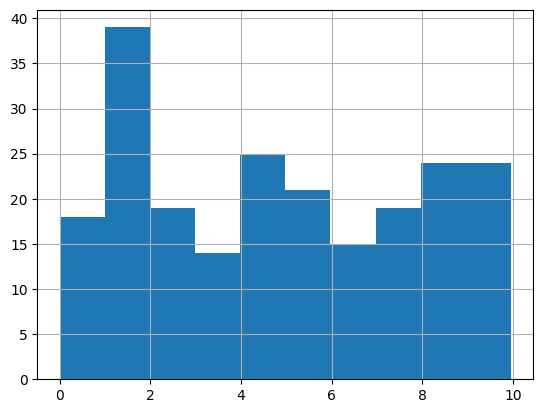

In [87]:
ds2_production_scores['NSCLC_PROphetScore'].hist()